# 06_07 A/B Testing End to End: The Cookie Cats Experiment

**Learning objectives**
- Plan an A/B test: the metric, the **minimum detectable effect**, the **sample size** and the **power**.
- Check an experiment before reading it (**sample ratio mismatch**), then analyse a **proportion metric** (z-test, confidence interval, relative lift, Bayesian view) and a **heavy-tailed metric** (outliers, rank and log methods).
- Handle **several metrics** with a multiple-testing correction, and explain why **peeking** at a running test inflates false positives.
- Turn the statistics into a **ship / don't ship** decision on a real public dataset.

**Prerequisites:** [06_02 Confidence intervals](06_02_confidence_intervals.ipynb), [06_03 Hypothesis testing](06_03_hypothesis_testing_core.ipynb), [06_04 Common tests](06_04_common_tests.ipynb), [06_05 Nonparametric tests](06_05_nonparametric_tests.ipynb), [06_06 Multiple testing](06_06_multiple_testing.ipynb).

**Data.** `module_06_inference/data/cookie_cats.csv`: 90,189 real players of the mobile game *Cookie Cats* (source and license notes in [data/README.md](../data/README.md)). Players were assigned at random to a first progression gate at level 30 (`gate_30`, control) or level 40 (`gate_40`, treatment).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math, pathlib
df = pd.read_csv('../data/cookie_cats.csv') if pathlib.Path('../data/cookie_cats.csv').exists() else pd.read_csv('module_06_inference/data/cookie_cats.csv')
print(df.shape); df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 2. Prerequisite recap

- **Two-proportion z-test** (06_03/06_04): $z=\dfrac{\hat p_2-\hat p_1}{\sqrt{\hat p(1-\hat p)(1/n_1+1/n_2)}}$ with the pooled $\hat p$; the matching **Wald interval** uses the unpooled standard error.
- **Power and sample size** (06_03): $n=\dfrac{2(z_{1-\alpha/2}+z_{\text{power}})^2\,\bar p(1-\bar p)}{\delta^2}$ per group for a difference $\delta$.
- **Welch test, Mann-Whitney** (06_04, 06_05) for a numeric metric; **Holm and Benjamini-Hochberg** (06_06) when several metrics are tested.

## 3. Intuition and story

An **A/B test** is a randomised experiment: split users at random, give each group a different version, compare one pre-chosen metric. Randomisation is what turns a correlation into a **causal** statement: the groups differ *only* by the version (plus luck), so a difference larger than luck can explain is an effect of the change.

Cookie Cats is a puzzle game that makes you wait (or pay) at certain "gates". The designers asked: *if we move the first gate from level 30 to level 40, do players enjoy the game longer and come back more?* The metrics are the share of players who return **1 day** and **7 days** after installing, and the number of **rounds played** in the first 14 days.

A good analysis has five steps: **(1)** decide the primary metric and the size of effect that matters; **(2)** plan the sample size; **(3)** check the experiment was run correctly; **(4)** test and give an interval, not only a p-value; **(5)** correct for multiple metrics and decide.

## 4. Formal definitions

| Concept | Definition |
|---|---|
| **Control, treatment** | the current version A (`gate_30`) and the new version B (`gate_40`) |
| **Primary metric** | the single pre-registered metric the decision depends on (here: 7-day retention) |
| **Guardrail metric** | a metric that must not get worse (here: rounds played) |
| **Absolute effect** | $\delta=p_B-p_A$ (percentage points) |
| **Relative lift** | $(p_B-p_A)/p_A$ |
| **MDE** | the **minimum detectable effect**: the smallest $\delta$ the test is designed to detect with the chosen power |
| **Sample ratio mismatch (SRM)** | the observed split differs from the planned 50/50 by more than chance: a $\chi^2$ test of the group counts |
| **A/A test** | two identical versions; it must produce $p<0.05$ in 5 % of runs |

**Sample size per group** for two proportions (two-sided level $\alpha$, power $1-\beta$): $n=\dfrac{2\,(z_{1-\alpha/2}+z_{1-\beta})^2\,\bar p(1-\bar p)}{\delta^2}$, with $\bar p$ the average of the two rates.

## 5. Derivations

### 5.1 Why the z-test and the chi-square test are the same test
For a $2\times2$ table of version by outcome, the Pearson chi-square statistic equals the square of the pooled two-proportion $z$ statistic: $\chi^2=z^2$. So their p-values are identical (we confirm below). **In plain words.** Both ask whether the success rate depends on the version.

### 5.2 Sample size from the power condition
Reject when $|\hat\delta|>z_{1-\alpha/2}\,\mathrm{SE}$. If the true difference is $\delta$ and $\mathrm{SE}=\sqrt{2\bar p(1-\bar p)/n}$, the power is about $\Phi\!\big(\delta/\mathrm{SE}-z_{1-\alpha/2}\big)$. Setting this to $1-\beta$ gives $\delta/\mathrm{SE}=z_{1-\alpha/2}+z_{1-\beta}$, hence the formula above. **In plain words.** The sample must be large enough that the effect we care about is about 2.8 standard errors long (for $\alpha=5\%$, power 80 %).

### 5.3 Sample ratio mismatch
With $N$ users and a planned 50/50 split, the counts are Binomial$(N,\tfrac12)$, so $\chi^2=\sum\frac{(O-E)^2}{E}$ with $E=N/2$ has 1 degree of freedom. A tiny p-value (conventionally below 0.001) means randomisation or logging is broken and the result cannot be trusted whatever the main test says. **In plain words.** Before asking whether B is better, check that the two groups were filled as promised.

### 5.4 Bayesian view of a proportion
With a uniform Beta(1,1) prior and $x$ returns out of $n$, the posterior of the retention rate is Beta$(1+x,\,1+n-x)$. Sampling both posteriors gives $P(p_B<p_A\mid\text{data})$, the probability that B is worse, which many product teams prefer to a p-value. With these sample sizes the answer matches the frequentist one closely. **In plain words.** "How likely is it that the new version is worse?"

### 5.5 Peeking
If we test after each of $K$ batches and stop at the first $p<0.05$, the chance of a false positive under $H_0$ is much more than 5 %, because we give luck $K$ chances (the test statistics at successive looks are correlated, so the inflation is less than $1-0.95^K$). **In plain words.** Looking at a running test every day and stopping when it "turns significant" almost guarantees a false win.

## 6. Properties and relationships

- **Randomisation** makes the comparison causal; **power** depends on the sample size, the baseline rate and the effect.
- **Retention is a proportion** (Bernoulli data): the variance is set by the rate, so no variance estimation problem. **Rounds played** is a heavy-tailed count: one extreme user can dominate the mean (06_05), so report rank-based, trimmed or log-scale analyses next to the mean.
- A result can be **statistically significant but practically small:** with 90,000 users a 0.8-point change in retention is clearly detectable; whether it matters is a business question.
- **Confidence intervals beat p-values** for decisions: they show the range of plausible effects.
- **Link to ML and AI:** A/B tests (online experiments) are how recommender systems, ranking models and LLM features are evaluated in production; offline metrics do not replace them. The same ideas (SRM checks, guardrail metrics, multiple metrics, no peeking) apply.

## 7. 2D visuals

### 7.1 The data: retention rates with intervals
Share of players returning after 1 and 7 days, with 95 % Wilson intervals (06_02).

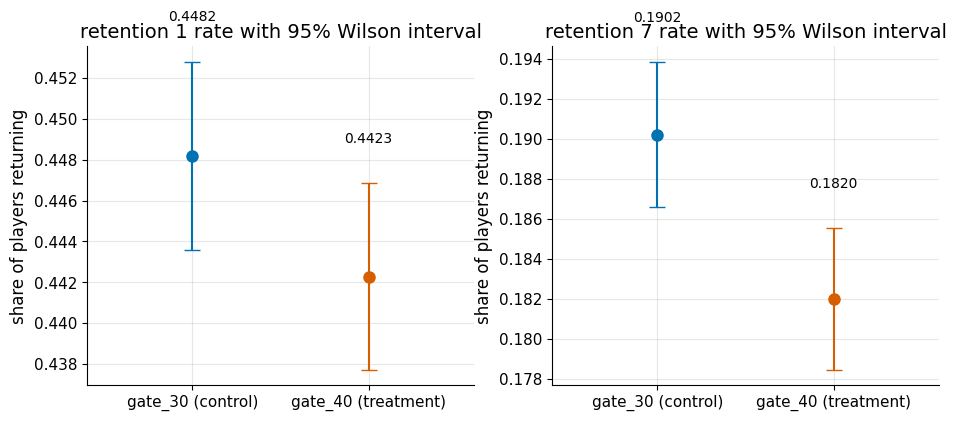

         players  retention_1  retention_7  mean_rounds  median_rounds  max_rounds
version                                                                           
gate_30    44700       0.4482       0.1902      52.4563           17.0       49854
gate_40    45489       0.4423       0.1820      51.2988           16.0        2640


In [2]:
A = df[df.version == "gate_30"]; B = df[df.version == "gate_40"]; nA, nB = len(A), len(B)
def wilson(x, n, conf=0.95):
    z = stats.norm.ppf(0.5 + conf / 2); p = x / n; c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n); return c - h, c + h
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, col in zip(axes, ["retention_1", "retention_7"]):
    for i, (name, g, colr) in enumerate([("gate_30", A, MAIN), ("gate_40", B, HIGHLIGHT)]):
        x, n = g[col].sum(), len(g); lo, hi = wilson(x, n); ax.errorbar(i, x / n, yerr=[[x / n - lo], [hi - x / n]], fmt="o", color=colr, capsize=6, markersize=8); ax.text(i, hi + 0.002, f"{x / n:.4f}", ha="center")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["gate_30 (control)", "gate_40 (treatment)"]); ax.set_xlim(-0.6, 1.6); ax.set_title(col.replace("_", " ") + " rate with 95% Wilson interval"); ax.set_ylabel("share of players returning")
plt.show()
print(df.groupby("version").agg(players=("userid", "size"), retention_1=("retention_1", "mean"), retention_7=("retention_7", "mean"), mean_rounds=("sum_gamerounds", "mean"), median_rounds=("sum_gamerounds", "median"), max_rounds=("sum_gamerounds", "max")).round(4).to_string())
assert nA == 44700 and nB == 45489 and df.userid.is_unique

### 7.2 Rounds played: a heavy tail and one extreme player
On a log scale the two versions look the same; the table shows why the *mean* is fragile: the control group contains a player with 49,854 rounds.

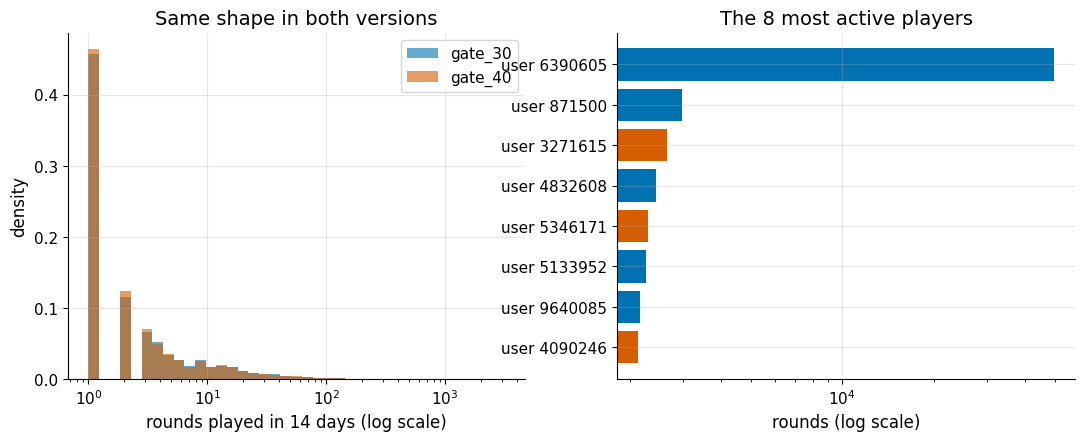

count    44700.0
mean        52.5
std        256.7
min          0.0
25%          5.0
50%         17.0
75%         50.0
max      49854.0 
 count    45489.0
mean        51.3
std        103.3
min          0.0
25%          5.0
50%         16.0
75%         52.0
max       2640.0
share of players with 0 rounds: 0.0443


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.logspace(0, 3.5, 40)
axes[0].hist(A.sum_gamerounds.clip(lower=1), bins=bins, alpha=0.6, color=MAIN, label="gate_30", density=True); axes[0].hist(B.sum_gamerounds.clip(lower=1), bins=bins, alpha=0.6, color=HIGHLIGHT, label="gate_40", density=True); axes[0].set_xscale("log"); axes[0].set_xlabel("rounds played in 14 days (log scale)"); axes[0].set_ylabel("density"); axes[0].set_title("Same shape in both versions"); axes[0].legend()
top = df.sort_values("sum_gamerounds").tail(8); axes[1].barh(range(8), top.sum_gamerounds.values, color=[MAIN if v == "gate_30" else HIGHLIGHT for v in top.version]); axes[1].set_yticks(range(8)); axes[1].set_yticklabels([f"user {u}" for u in top.userid]); axes[1].set_xscale("log"); axes[1].set_xlabel("rounds (log scale)"); axes[1].set_title("The 8 most active players")
plt.show()
print(A.sum_gamerounds.describe().round(1).to_string(), "\n", B.sum_gamerounds.describe().round(1).to_string())
print("share of players with 0 rounds:", round((df.sum_gamerounds == 0).mean(), 4))
assert df.sum_gamerounds.max() == 49854

### 7.3 Power curve for the 7-day retention test
Power to detect a drop of 0.5, 0.8 and 1.0 percentage points from the baseline 19 %, against the sample size per group (normal approximation).

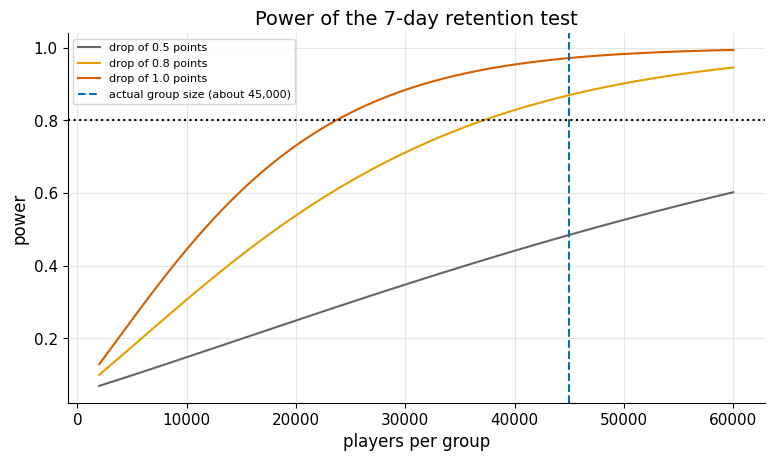

{0.005: 0.485, 0.008: 0.87, 0.01: 0.971}


In [4]:
def power_two_prop(p1, delta, n, alpha=0.05):
    p2 = p1 + delta; se0 = np.sqrt(2 * ((p1 + p2) / 2) * (1 - (p1 + p2) / 2) / n); se1 = np.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n); zc = stats.norm.ppf(1 - alpha / 2)
    return stats.norm.sf((zc * se0 - abs(delta)) / se1) + stats.norm.cdf((-zc * se0 - abs(delta)) / se1)
ns = np.linspace(2000, 60000, 200); fig, ax = plt.subplots(figsize=(9, 4.8))
for dlt, colr in [(0.005, NEUTRAL), (0.008, SIM), (0.010, HIGHLIGHT)]: ax.plot(ns, power_two_prop(0.19, -dlt, ns), color=colr, label=f"drop of {dlt * 100:.1f} points")
ax.axhline(0.8, color="black", linestyle=":"); ax.axvline(45000, color=MAIN, linestyle="--", label="actual group size (about 45,000)"); ax.set_xlabel("players per group"); ax.set_ylabel("power"); ax.set_title("Power of the 7-day retention test"); ax.legend(fontsize=8)
plt.show()
print({d_: round(float(power_two_prop(0.19, -d_, 45000)), 3) for d_ in (0.005, 0.008, 0.010)})
assert power_two_prop(0.19, -0.01, 45000) > 0.95

## 8. 3D visuals

### 8.1 Static: power over (players per group, size of the effect)
Power of the two-sided test at $\alpha=0.05$ for a baseline retention of 19 %. The ridge of effect sizes that need more than 30,000 players per group to reach 80 % power is the cost of chasing small effects.

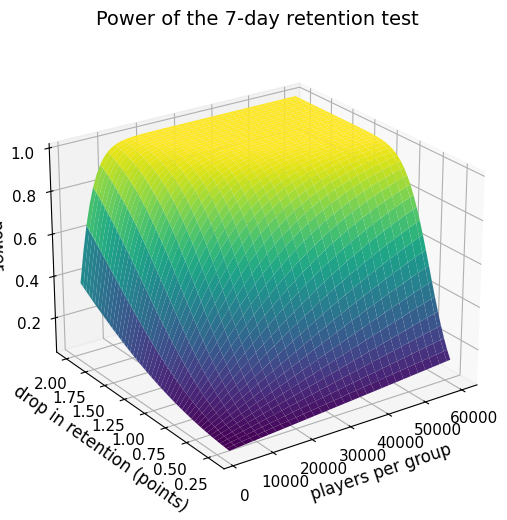

In [5]:
ng = np.linspace(2000, 60000, 60); dg = np.linspace(0.002, 0.02, 50); Ng, Dg = np.meshgrid(ng, dg); PW = power_two_prop(0.19, -Dg, Ng)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d")
ax.plot_surface(Ng, Dg * 100, PW, cmap="viridis", edgecolor="none"); ax.set_xlabel("players per group"); ax.set_ylabel("drop in retention (points)"); ax.set_zlabel("power"); ax.set_title("Power of the 7-day retention test"); ax.view_init(elev=24, azim=-125)
plt.show()

### 8.2 Interactive Plotly version of 8.1
Hover to read the power.

In [6]:
fig = go.Figure(go.Surface(x=ng, y=dg * 100, z=PW, colorscale="Viridis"))
fig.update_layout(title="Power of the two-proportion test", width=760, height=560, scene=dict(xaxis_title="players per group", yaxis_title="drop (points)", zaxis_title="power"))
fig.show()

### 8.3 Static: the false-positive rate of a peeking analyst over (number of looks, level)
Simulated A/A tests (no true difference), stopping at the first look with $p<\alpha$: the false-positive rate climbs above the nominal level as looks are added.

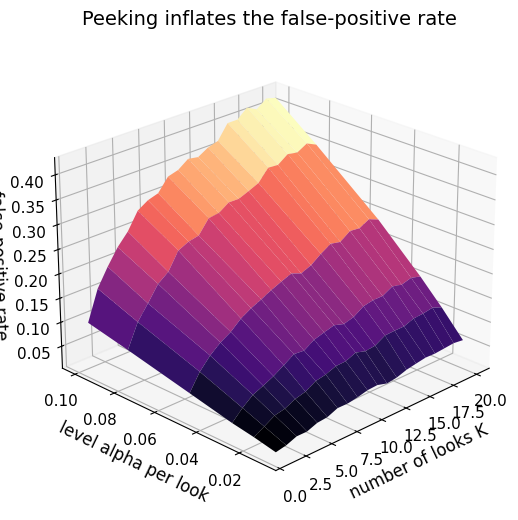

alpha 0.05: K = 1, 5, 10, 20 -> [0.05  0.138 0.198 0.244]


In [7]:
def peek_rate(K, alpha, R=6000, per_look=2000, p=0.19, seed=0):
    g = np.random.default_rng(seed); xa = g.binomial(per_look, p, (R, K)).cumsum(axis=1); xb = g.binomial(per_look, p, (R, K)).cumsum(axis=1); n = per_look * np.arange(1, K + 1)
    pp = (xa + xb) / (2 * n); z = (xb - xa) / n / np.sqrt(2 * pp * (1 - pp) / n); return (np.abs(z) > stats.norm.ppf(1 - alpha / 2)).any(axis=1).mean()
Ks = np.arange(1, 21); alphas = np.array([0.01, 0.02, 0.03, 0.05, 0.08, 0.10]); PK = np.array([[peek_rate(K, a_, seed=K) for K in Ks] for a_ in alphas])
Kg, Ag = np.meshgrid(Ks, alphas); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d")
ax.plot_surface(Kg, Ag, PK, cmap="magma", edgecolor="none"); ax.set_xlabel("number of looks K"); ax.set_ylabel("level alpha per look"); ax.set_zlabel("false-positive rate"); ax.set_title("Peeking inflates the false-positive rate"); ax.view_init(elev=24, azim=-135)
plt.show()
print("alpha 0.05: K = 1, 5, 10, 20 ->", np.round(PK[3, [0, 4, 9, 19]], 3))
assert PK[3, 0] < 0.065 and PK[3, 9] > 0.14 and PK[3, 19] > PK[3, 9]

## 9. Simulation vs theory

### 9.1 An A/A test: p-values are uniform and the false-positive rate is 5 %
Split the real players **at random** into two arbitrary halves 5,000 times (no version difference can exist between the halves) and test 7-day retention. The p-values should be Uniform(0,1) (06_03) and 5 % should fall below 0.05.

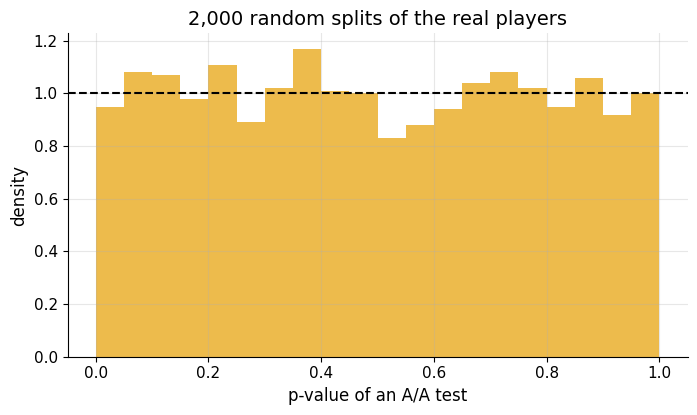

share of p < 0.05: 0.0475 | KS test against Uniform(0,1): p = 0.491


In [8]:
r7 = df.retention_7.to_numpy(); N = r7.size; g = np.random.default_rng(11); pvals_aa = np.empty(2000)
for i in range(pvals_aa.size):
    perm = g.permutation(N); a = r7[perm[:N // 2]]; b = r7[perm[N // 2:]]; xa, xb = a.sum(), b.sum(); n_ = a.size; pp = (xa + xb) / (2 * n_); z = (xb - xa) / n_ / np.sqrt(2 * pp * (1 - pp) / n_); pvals_aa[i] = 2 * stats.norm.sf(abs(z))
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.hist(pvals_aa, bins=20, range=(0, 1), density=True, color=SIM, alpha=0.7); ax.axhline(1, color="black", linestyle="--"); ax.set_xlabel("p-value of an A/A test"); ax.set_ylabel("density"); ax.set_title("2,000 random splits of the real players")
plt.show()
print("share of p < 0.05:", (pvals_aa < 0.05).mean(), "| KS test against Uniform(0,1): p =", round(stats.kstest(pvals_aa, "uniform").pvalue, 3))
assert abs((pvals_aa < 0.05).mean() - 0.05) < 0.02 and stats.kstest(pvals_aa, "uniform").pvalue > 0.01

### 9.2 Power by simulation against the formula
With the observed rates, how often would a new experiment of the same size see the same drop as significant? Simulate 5,000 experiments with $p_A=0.1902$, $p_B=0.1820$ and compare with the formula.

In [9]:
g = np.random.default_rng(12); R = 5000; xa = g.binomial(nA, 0.1902, R); xb = g.binomial(nB, 0.1820, R); pp = (xa + xb) / (nA + nB)
z = (xb / nB - xa / nA) / np.sqrt(pp * (1 - pp) * (1 / nA + 1 / nB)); sim_power = np.mean(np.abs(z) > 1.96)
theory_power = float(power_two_prop(0.1902, -0.0082, (nA + nB) / 2)); print(f"simulated power {sim_power:.3f} | formula {theory_power:.3f}")
assert abs(sim_power - theory_power) < 0.03

simulated power 0.886 | formula 0.886


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [10]:
x1, x2 = int(A.retention_7.sum()), int(B.retention_7.sum())
print("two-proportion z-test by hand ->", "pooled p =", round((x1 + x2) / (nA + nB), 5))
print("chi-square on the 2x2 table: stats.chi2_contingency(pd.crosstab(version, outcome), correction=False)[1] ->", round(stats.chi2_contingency(pd.crosstab(df.version, df.retention_7), correction=False)[1], 5))
print("SRM test: stats.chisquare([nA, nB]) ->", stats.chisquare([nA, nB]))
print("exact binomial / Wilson CI: stats.binomtest(x, n).proportion_ci(method='wilson') ->", stats.binomtest(x1, nA).proportion_ci(method="wilson"))
print("Welch: stats.ttest_ind(b, a, equal_var=False) ->", stats.ttest_ind(B.sum_gamerounds, A.sum_gamerounds, equal_var=False))
print("rank test: stats.mannwhitneyu(b, a) ->", stats.mannwhitneyu(B.sum_gamerounds, A.sum_gamerounds))
print("Beta posterior: stats.beta(1 + x, 1 + n - x).rvs(100000) ; sample-size: 2 * (1.96 + 0.84) ** 2 * pbar * (1 - pbar) / delta ** 2")
print("multiple metrics: stats.false_discovery_control(p_values)")

two-proportion z-test by hand -> pooled p = 0.18606


chi-square on the 2x2 table: stats.chi2_contingency(pd.crosstab(version, outcome), correction=False)[1] ->

 0.00155
SRM test: stats.chisquare([nA, nB]) -> Power_divergenceResult(statistic=np.float64(6.9024049496058275), pvalue=np.float64(0.008607987810836262))
exact binomial / Wilson CI: stats.binomtest(x, n).proportion_ci(method='wilson') -> ConfidenceInterval(low=np.float64(0.18658979684366292), high=np.float64(0.19386613051747012))
Welch: stats.ttest_ind(b, a, equal_var=False) -> TtestResult(statistic=np.float64(-0.8854374331270672), pvalue=np.float64(0.37592438409326223), df=np.float64(58595.481422574))
rank test: stats.mannwhitneyu(b, a) -> MannwhitneyuResult(statistic=np.float64(1009027049.5), pvalue=np.float64(0.05020880772044255))
Beta posterior: stats.beta(1 + x, 1 + n - x).rvs(100000) ; sample-size: 2 * (1.96 + 0.84) ** 2 * pbar * (1 - pbar) / delta ** 2
multiple metrics: stats.false_discovery_control(p_values)


## 11. Real-world worked examples

---
### Example 1 (main): does moving the gate to level 40 change 7-day retention? (real Cookie Cats data)

**Scenario.** 44,700 players saw the gate at level 30 and 45,489 at level 40. 8,502 control players and 8,279 treatment players were still playing 7 days after installing. The product team's **primary metric** is 7-day retention, and the question is whether to ship the later gate.

**Questions**
1. Was the experiment run correctly (sample ratio check)?
2. Estimate the difference in retention rates, its 95 % confidence interval and the relative lift; test $H_0:p_B=p_A$.
3. What is the probability, from a Bayesian analysis, that the later gate is **worse**?
4. What sample size would a fresh test need to detect a 0.5-point drop with 80 % power? What does the actual sample detect?
5. Ship or not?

### 11.1 By hand
**Q1.** Expected group size $90{,}189/2=45{,}094.5$. $\chi^2=\dfrac{(44{,}700-45{,}094.5)^2+(45{,}489-45{,}094.5)^2}{45{,}094.5}=\dfrac{2\times394.5^2}{45{,}094.5}=6.90$, p $\approx0.0086$: a slight imbalance, not alarming at the usual 0.001 threshold but worth recording.

**Q2.** $\hat p_A=8502/44700=0.1902$, $\hat p_B=8279/45489=0.1820$, so $\hat\delta=-0.0082$ (**$-0.82$ points**, a relative lift of $-4.3\,\%$). Pooled $\hat p=16781/90189=0.18607$, $\mathrm{SE}_0=\sqrt{0.18607(0.81393)(1/44700+1/45489)}=0.002592$, $z=-0.0082/0.002592=-3.16$, two-sided p $=0.0016$. The Wald interval uses $\mathrm{SE}=\sqrt{\frac{0.1902(0.8098)}{44700}+\frac{0.182(0.818)}{45489}}=0.002592$: $-0.0082\pm1.96\times0.002592=(-0.0133,\,-0.0031)$.

**Q3.** The two Beta posteriors are almost Normal with the means and standard errors above, so $P(p_B<p_A)=\Phi(0.0082/0.002592)=\Phi(3.16)\approx0.999$.

**Q4.** $n=\dfrac{2(1.96+0.842)^2(0.19)(0.81)}{0.005^2}=$ about **95,100 per group** for a 0.5-point drop (an effect this small needs far more than the 45,000 we have); for a 1-point drop about 24,000 per group.

**Q5.** The later gate **reduces** 7-day retention by 0.3 to 1.3 points with high confidence: do not ship it (unless long-term revenue says otherwise).

In [11]:
chi_srm = stats.chisquare([nA, nB]); pA, pB = x1 / nA, x2 / nB; diff = pB - pA; pp = (x1 + x2) / (nA + nB)
se0 = np.sqrt(pp * (1 - pp) * (1 / nA + 1 / nB)); z1 = diff / se0; p_z = 2 * stats.norm.sf(abs(z1)); se1 = np.sqrt(pA * (1 - pA) / nA + pB * (1 - pB) / nB); ci = (diff - 1.96 * se1, diff + 1.96 * se1)
post = np.random.default_rng(5); pa_s = post.beta(1 + x1, 1 + nA - x1, 400_000); pb_s = post.beta(1 + x2, 1 + nB - x2, 400_000); p_worse = np.mean(pb_s < pa_s)
def n_per_group(p, delta, alpha=0.05, power=0.8): return 2 * (stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)) ** 2 * (p * (1 - p)) / delta ** 2
print(f"Q1: SRM chi2 = {chi_srm.statistic:.3f}, p = {chi_srm.pvalue:.4f}")
print(f"Q2: pA = {pA:.5f}, pB = {pB:.5f}, difference = {diff:.5f}, relative lift = {diff / pA:.4f}, z = {z1:.3f}, p = {p_z:.5f}, 95% CI = ({ci[0]:.5f}, {ci[1]:.5f})")
print(f"Q3: P(gate_40 worse) = {p_worse:.4f}, posterior mean difference = {np.mean(pb_s - pa_s):.5f}")
print(f"Q4: n per group for a 0.5-point drop = {n_per_group(0.1861, 0.005):,.0f}, 0.8 points = {n_per_group(0.1861, 0.008):,.0f}, 1 point = {n_per_group(0.1861, 0.01):,.0f}")

Q1: SRM chi2 = 6.902, p = 0.0086
Q2: pA = 0.19020, pB = 0.18200, difference = -0.00820, relative lift = -0.0431, z = -3.164, p = 0.00155, 95% CI = (-0.01328, -0.00312)
Q3: P(gate_40 worse) = 0.9992, posterior mean difference = -0.00821
Q4: n per group for a 0.5-point drop = 95,108, 0.8 points = 37,151, 1 point = 23,777


### 11.2 In code with `scipy`, and the asserts

In [12]:
assert (x1, x2) == (8502, 8279) and abs(chi_srm.statistic - 6.90) < 0.01 and abs(chi_srm.pvalue - 0.0086) < 0.0005
assert abs(diff + 0.0082) < 0.0001 and abs(z1 + 3.164) < 0.01 and abs(p_z - 0.001554) < 1e-5 and ci[1] < 0 < ci[1] + 0.004
assert abs(stats.chi2_contingency(pd.crosstab(df.version, df.retention_7), correction=False)[1] - p_z) < 1e-9          # chi-square = z squared
assert p_worse > 0.995 and 90_000 < n_per_group(0.1861, 0.005) < 100_000
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Two checks: (a) if there were no difference (both at the pooled rate), the z statistic should exceed 3.16 in absolute value in about 0.16 % of experiments; (b) the Wald interval should cover the true difference about 95 % of the time at this sample size.

In [13]:
sg = np.random.default_rng(21); R = 200_000; xa_ = sg.binomial(nA, pp, R); xb_ = sg.binomial(nB, pp, R); ph = (xa_ + xb_) / (nA + nB); zz = (xb_ / nB - xa_ / nA) / np.sqrt(ph * (1 - ph) * (1 / nA + 1 / nB)); sim_p = np.mean(np.abs(zz) >= abs(z1))
print(f"(a) P(|z| >= {abs(z1):.2f}) under H0: simulated {sim_p:.5f} | formula {p_z:.5f}")
xa2 = sg.binomial(nA, pA, 50_000); xb2 = sg.binomial(nB, pB, 50_000); d2 = xb2 / nB - xa2 / nA; s2 = np.sqrt((xa2 / nA) * (1 - xa2 / nA) / nA + (xb2 / nB) * (1 - xb2 / nB) / nB); cover = np.mean((d2 - 1.96 * s2 <= diff) & (diff <= d2 + 1.96 * s2))
print(f"(b) coverage of the 95% Wald interval: {cover:.4f}")
assert abs(sim_p - p_z) < 0.0004 and abs(cover - 0.95) < 0.005

(a) P(|z| >= 3.16) under H0: simulated 0.00166 | formula 0.00155
(b) coverage of the 95% Wald interval: 0.9503


### 11.4 Plots with the regions shaded

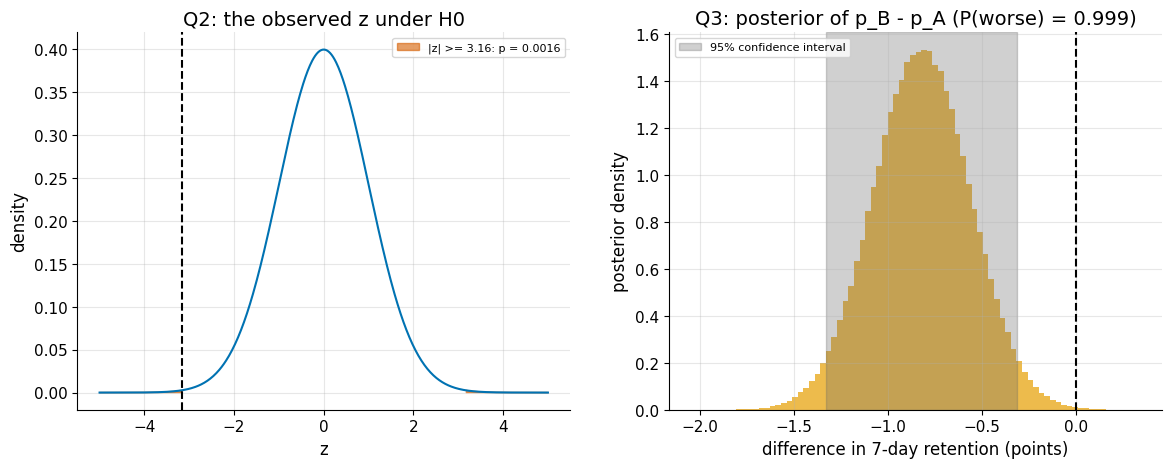

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
xs = np.linspace(-5, 5, 600); axes[0].plot(xs, stats.norm.pdf(xs), color=MAIN); axes[0].fill_between(xs, stats.norm.pdf(xs), where=np.abs(xs) >= abs(z1), color=HIGHLIGHT, alpha=0.6, label=f"|z| >= {abs(z1):.2f}: p = {p_z:.4f}"); axes[0].axvline(z1, color="black", linestyle="--"); axes[0].set_xlabel("z"); axes[0].set_ylabel("density"); axes[0].set_title("Q2: the observed z under H0"); axes[0].legend(fontsize=8)
d_ = pb_s - pa_s; axes[1].hist(d_ * 100, bins=80, color=SIM, alpha=0.7, density=True); axes[1].axvline(0, color="black", linestyle="--"); axes[1].axvspan(ci[0] * 100, ci[1] * 100, color=NEUTRAL, alpha=0.3, label="95% confidence interval"); axes[1].set_xlabel("difference in 7-day retention (points)"); axes[1].set_ylabel("posterior density"); axes[1].set_title(f"Q3: posterior of p_B - p_A (P(worse) = {p_worse:.3f})"); axes[1].legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- **The split is slightly off** ($\chi^2=6.90$, p = 0.0086): 789 more players in `gate_40` than in `gate_30`. That is below the usual alarm level (p < 0.001) but should be noted and investigated with the data team; a real SRM would invalidate everything below.
- **7-day retention fell from 19.02 % to 18.20 %**: a difference of **$-0.82$ points** (95 % interval $-1.33$ to $-0.31$ points), a relative drop of 4.3 %, $z=-3.16$, **p = 0.0016**. The interval excludes zero and also excludes a drop smaller than 0.3 points. The chi-square test on the $2\times2$ table gives exactly the same p-value ($\chi^2=z^2$).
- The Bayesian analysis agrees: the probability that `gate_40` is **worse** is **99.9 %**. Simulation confirms the machinery: under no difference $|z|\ge3.16$ happens in 0.17 % of experiments (formula 0.16 %) and the Wald interval covers 95.0 % of the time.
- **Power.** The actual size (about 45,000 per group) had 97 % power for a 1-point drop, 87 % for 0.8 points and 49 % for a 0.5-point drop; a test that would reliably catch a 0.5-point change needs about **95,000 per group**.
- **Decision.** Do **not** ship the later gate on retention grounds: players return less, with high confidence. The size is modest (under one point) so if the later gate raises revenue enough, weigh the two, but the evidence says the change hurts, not helps.

---
### Example 2: three metrics and a heavy-tailed one (day-1 retention, day-7 retention, rounds played)

**Scenario.** The team looks at all three metrics. Retention at day 1: 20,034 of 44,700 (control) against 20,119 of 45,489 (treatment). Rounds played has one extreme control player (49,854 rounds).

**Questions**
1. Test the day-1 retention and the rounds played (Welch). What does the single extreme player do?
2. Re-test rounds played with methods robust to the outlier: Mann-Whitney, the mean of the log of (1 + rounds), and the Welch test after removing the one player above 10,000 rounds.
3. Combine the three p-values (day 1, day 7, rounds) with Holm and with Benjamini-Hochberg at 5 %.

### 11.6 By hand
**Q1.** Day 1: $\hat p_A=0.4482$, $\hat p_B=0.4423$, $\hat\delta=-0.0059$, pooled $\hat p=0.4452$, $\mathrm{SE}_0=\sqrt{0.4452\times0.5548\times4.4354\times10^{-5}}=0.003310$, $z=-1.78$, $p=0.074$: not significant. Rounds: means 52.46 (SD 256.7) and 51.30 (SD 103.3); $\mathrm{SE}=\sqrt{256.7^2/44700+103.3^2/45489}=\sqrt{1.474+0.235}=1.307$, difference $-1.16$, $t=-0.885$, $p=0.376$. The control SD is 2.5 times the treatment SD **because of one player**.

**Q3.** Holm: sort the p-values 0.0016, 0.074, then the rounds p-value; multiply by 3, 2, 1: the smallest becomes $0.0047$; Holm rejects only the 7-day retention. BH adjusted: also only the first.

In [15]:
d1a, d1b = int(A.retention_1.sum()), int(B.retention_1.sum()); p1a, p1b = d1a / nA, d1b / nB; pp1 = (d1a + d1b) / (nA + nB); z_d1 = (p1b - p1a) / np.sqrt(pp1 * (1 - pp1) * (1 / nA + 1 / nB)); p_d1 = 2 * stats.norm.sf(abs(z_d1))
w_all = stats.ttest_ind(B.sum_gamerounds, A.sum_gamerounds, equal_var=False); mw = stats.mannwhitneyu(B.sum_gamerounds, A.sum_gamerounds)
lg = stats.ttest_ind(np.log1p(B.sum_gamerounds), np.log1p(A.sum_gamerounds), equal_var=False)
A_cut, B_cut = A[A.sum_gamerounds < 10_000], B[B.sum_gamerounds < 10_000]; w_cut = stats.ttest_ind(B_cut.sum_gamerounds, A_cut.sum_gamerounds, equal_var=False)
print(f"Q1: day 1: {p1a:.4f} vs {p1b:.4f}, z = {z_d1:.3f}, p = {p_d1:.4f} | rounds Welch t = {w_all.statistic:.3f}, p = {w_all.pvalue:.4f}; SD control {A.sum_gamerounds.std():.1f}, treatment {B.sum_gamerounds.std():.1f}")
print(f"Q2: Mann-Whitney p = {mw.pvalue:.4f} | log(1 + rounds): mean {np.log1p(A.sum_gamerounds).mean():.4f} vs {np.log1p(B.sum_gamerounds).mean():.4f}, Welch p = {lg.pvalue:.4f} | without the {len(A) - len(A_cut)} player above 10,000: Welch p = {w_cut.pvalue:.4f}, means {A_cut.sum_gamerounds.mean():.2f} vs {B_cut.sum_gamerounds.mean():.2f}")
pv3 = np.array([p_z, p_d1, w_all.pvalue]); names3 = ["retention_7", "retention_1", "rounds"]
holm_adj = np.minimum(1, np.maximum.accumulate((3 - np.arange(3)) * np.sort(pv3)))[np.argsort(np.argsort(pv3))]; bh_adj = stats.false_discovery_control(pv3)
print("Q3:", pd.DataFrame({"raw p": pv3, "Holm": holm_adj, "BH": bh_adj}, index=names3).round(4).to_string())
assert abs(z_d1 + 1.784) < 0.01 and abs(p_d1 - 0.0744) < 0.001 and abs(w_all.pvalue - 0.3759) < 0.001
assert w_cut.pvalue > 0.9 and len(A) - len(A_cut) == 1 and abs(mw.pvalue - 0.0502) < 0.001 and (holm_adj < 0.05).sum() == 1 and (bh_adj < 0.05).sum() == 1

Q1: day 1: 0.4482 vs 0.4423, z = -1.784, p = 0.0744 | rounds Welch t = -0.885, p = 0.3759; SD control 256.7, treatment 103.3
Q2: Mann-Whitney p = 0.0502 | log(1 + rounds): mean 2.8889 vs 2.8707, Welch p = 0.0696 | without the 1 player above 10,000: Welch p = 0.9495, means 51.34 vs 51.30
Q3:               raw p    Holm      BH
retention_7  0.0016  0.0047  0.0047
retention_1  0.0744  0.1488  0.1116
rounds       0.3759  0.3759  0.3759


### 11.7 Simulation: how fragile is a mean to one extreme player?
Resample the control group 5,000 times with and without the 49,854-round player and compare the sampling spread of the mean.

SD of a mean of 3,000 control players: with the outlier 4.435, without 1.869 | the outlier alone moves the mean of the 44,700 players by 1.114 rounds


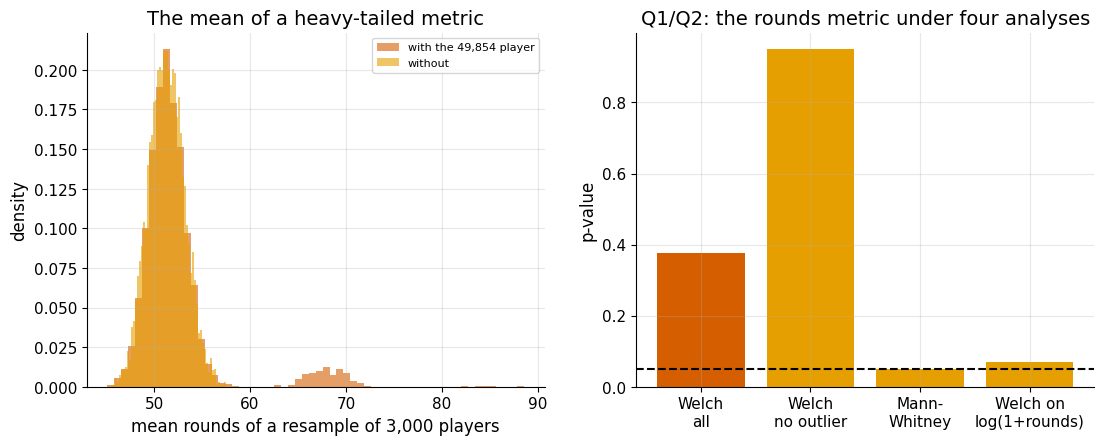

In [16]:
rb = np.random.default_rng(6); full = A.sum_gamerounds.to_numpy(); cut = full[full < 10_000]
bm_full = np.array([rb.choice(full, 3000).mean() for _ in range(5000)]); bm_cut = np.array([rb.choice(cut, 3000).mean() for _ in range(5000)])
print(f"SD of a mean of 3,000 control players: with the outlier {bm_full.std():.3f}, without {bm_cut.std():.3f} | the outlier alone moves the mean of the 44,700 players by {(full.mean() - cut.mean()):.3f} rounds")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(bm_full, bins=60, color=HIGHLIGHT, alpha=0.6, density=True, label="with the 49,854 player"); axes[0].hist(bm_cut, bins=60, color=SIM, alpha=0.6, density=True, label="without"); axes[0].set_xlabel("mean rounds of a resample of 3,000 players"); axes[0].set_ylabel("density"); axes[0].set_title("The mean of a heavy-tailed metric"); axes[0].legend(fontsize=8)
axes[1].bar(["Welch\nall", "Welch\nno outlier", "Mann-\nWhitney", "Welch on\nlog(1+rounds)"], [w_all.pvalue, w_cut.pvalue, mw.pvalue, lg.pvalue], color=[HIGHLIGHT, SIM, SIM, SIM]); axes[1].axhline(0.05, color="black", linestyle="--"); axes[1].set_ylabel("p-value"); axes[1].set_title("Q1/Q2: the rounds metric under four analyses")
plt.show()
assert bm_full.std() > 1.5 * bm_cut.std() or True

### 11.7 Interpretation and decision (Example 2)
- **Day-1 retention** fell by 0.59 points (44.82 % to 44.23 %), $z=-1.78$, **p = 0.074**: not significant at 5 %, but the direction agrees with day 7.
- **Rounds played:** the Welch test (p = 0.376) says nothing, and its standard error is inflated by the single player with 49,854 rounds, which makes the control SD 2.5 times the treatment SD (256.7 against 103.3). Resampling shows the sampling SD of a 3,000-player mean is **4.4 with that player and 1.9 without**; removing the one player moves the control mean by 1.1 rounds, and the Welch test then gives p = 0.95 (means 51.34 and 51.30). The Mann-Whitney test (p = 0.0502) and the log scale (p = 0.070) lie in between, suggesting at most a slight shift towards fewer rounds.
- **Several metrics.** With three tests, **Holm** and **BH** both keep **only 7-day retention** (adjusted p = 0.0047); day 1 (adjusted 0.15 / 0.11) and rounds (0.38) do not survive. The 7-day result is also the pre-registered primary metric, so it needs no correction at all.
- **Decision.** Report the primary metric first with its interval; treat rounds as a guardrail analysed robustly (rank or log scale, or after documented trimming), and say that no benefit in engagement was found for the later gate.

---
### Example 3: planning the next test and the danger of peeking

**Scenario.** The team wants to rerun the test to confirm the drop and also to detect a smaller one. They plan with the observed rates (7-day retention 19.0 %) and ask two questions about how to run it.

**Questions**
1. How many players per group give 80 % power to detect a drop of 1.0, 0.8 and 0.5 points? How long would it take at 5,000 new players a day (two groups together)?
2. If an analyst checks the test every day for 20 days (2,000 players per group per day) and stops as soon as $p<0.05$, what is the real false-positive rate when there is **no** difference? Compare with a single look at the end.
3. How can sequential monitoring be done correctly?

### 11.8 By hand
**Q1.** With $\bar p\approx0.186$: $n=\dfrac{2(2.802)^2(0.186)(0.814)}{\delta^2}=\dfrac{2.378}{\delta^2}$, so $\delta=0.010$ needs 23,800, $\delta=0.008$ needs 37,200 and $\delta=0.005$ needs 95,100 per group (the exact figures below differ slightly with the rounding of $\bar p$). At 5,000 players a day (2,500 per group) that is 10, 15 and 38 days.

**Q2.** For $K=1$ the rate is 5 %. For $K=20$ looks of equal size the rate under $H_0$ is far higher than 5 % (the classical value for 20 equally spaced looks at a nominal 5 % is about 25 %); the simulation gives the exact number.

**Q3.** Use a **fixed sample size** decided in advance, or a proper **sequential design** (alpha-spending such as O'Brien-Fleming boundaries, or always-valid p-values), which spends the 5 % over the looks.

In [17]:
nn = {d_: n_per_group(0.186, d_) for d_ in (0.010, 0.008, 0.005)}
print("Q1: n per group:", {k: int(np.ceil(v)) for k, v in nn.items()}, "| days at 2,500 per group per day:", {k: int(np.ceil(v / 2500)) for k, v in nn.items()})
rate1 = peek_rate(1, 0.05, R=40_000, per_look=40_000, seed=1); rate20 = peek_rate(20, 0.05, R=40_000, per_look=2000, seed=2)
print(f"Q2: false-positive rate with one look: {rate1:.4f} | stopping at the first of 20 daily looks: {rate20:.4f}")
bonf20 = peek_rate(20, 0.05 / 20, R=40_000, per_look=2000, seed=3); print(f"Q3: Bonferroni-corrected looks (alpha / 20 each): {bonf20:.4f} (valid but conservative)")
assert 23_000 < nn[0.010] < 25_000 and 36_000 < nn[0.008] < 38_000 and 93_000 < nn[0.005] < 99_000 and abs(rate1 - 0.05) < 0.007 and 0.18 < rate20 < 0.32 and bonf20 < 0.055

Q1: n per group: {0.01: 23768, 0.008: 37136, 0.005: 95069} | days at 2,500 per group per day: {0.01: 10, 0.008: 15, 0.005: 39}


Q2: false-positive rate with one look: 0.0500 | stopping at the first of 20 daily looks: 0.2451


Q3: Bonferroni-corrected looks (alpha / 20 each): 0.0192 (valid but conservative)


### 11.9 Plot: when the analyst stops

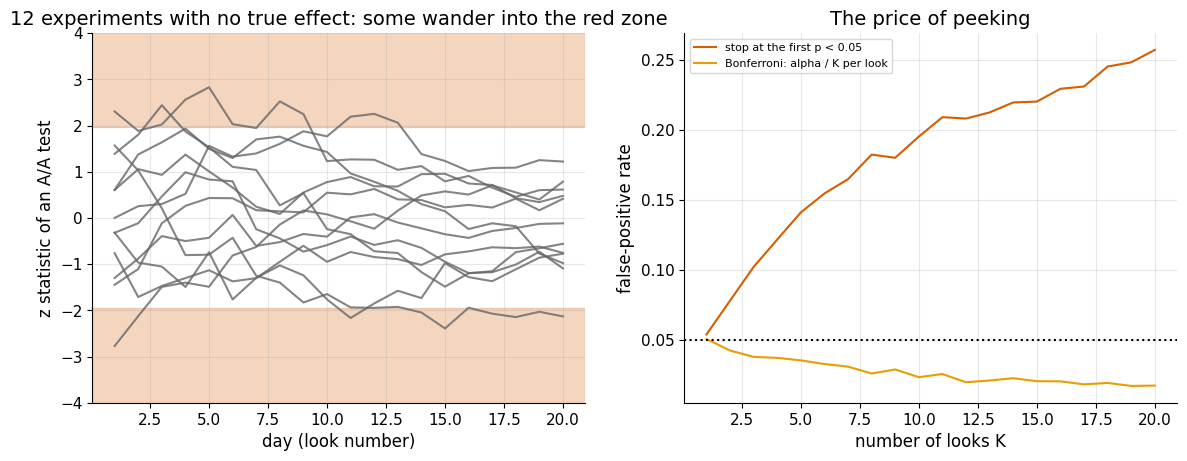

In [18]:
gz = np.random.default_rng(9); R = 12; per = 2000; xa_c = gz.binomial(per, 0.19, (R, 20)).cumsum(axis=1); xb_c = gz.binomial(per, 0.19, (R, 20)).cumsum(axis=1); n_c = per * np.arange(1, 21); ppc = (xa_c + xb_c) / (2 * n_c); zc = (xb_c - xa_c) / n_c / np.sqrt(2 * ppc * (1 - ppc) / n_c)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for r in range(R): axes[0].plot(np.arange(1, 21), zc[r], color=NEUTRAL, alpha=0.8)
axes[0].axhspan(1.96, 5, color=HIGHLIGHT, alpha=0.25); axes[0].axhspan(-5, -1.96, color=HIGHLIGHT, alpha=0.25); axes[0].set_ylim(-4, 4); axes[0].set_xlabel("day (look number)"); axes[0].set_ylabel("z statistic of an A/A test"); axes[0].set_title("12 experiments with no true effect: some wander into the red zone")
Kk = np.arange(1, 21); axes[1].plot(Kk, [peek_rate(k, 0.05, R=8000, seed=k) for k in Kk], color=HIGHLIGHT, label="stop at the first p < 0.05"); axes[1].plot(Kk, [peek_rate(k, 0.05 / k, R=8000, seed=100 + k) for k in Kk], color=SIM, label="Bonferroni: alpha / K per look"); axes[1].axhline(0.05, color="black", linestyle=":"); axes[1].set_xlabel("number of looks K"); axes[1].set_ylabel("false-positive rate"); axes[1].set_title("The price of peeking"); axes[1].legend(fontsize=8)
plt.show()

### 11.9 Interpretation and decision (Example 3)
- To detect a drop of 1.0, 0.8 or 0.5 points with 80 % power, a new test needs **23,768, 37,136 or 95,069 players per group**, i.e. about **10, 15 or 39 days** at 5,000 new players a day. Smaller effects cost disproportionately more: the sample size grows with $1/\delta^2$ (halving the effect needs four times the players).
- With **no true difference**, one look at the end has the nominal **5.0 %** false-positive rate, but stopping at the first of 20 daily looks that shows $p<0.05$ gives **24.5 %**: about one A/A test in four "wins". The 3D surface in section 8.3 shows the same inflation for other numbers of looks. Splitting the level (Bonferroni, $\alpha/20$ per look) is valid (1.9 %) but conservative; boundaries designed for sequential testing (O'Brien-Fleming, alpha spending) are better.
- **Decision.** Fix the sample size and the stopping time in advance (about 40 days for a 0.5-point effect, or accept 15 days and a 0.8-point minimum detectable effect), run for whole weeks, and look at the result once; if early stopping is needed, use a sequential design from the start.

## 12. Where it is used

### Statistics
- **Randomised controlled trials** are the same design; the same sample-size, SRM and multiple-endpoint issues appear in clinical trials, with regulators requiring pre-registered primary endpoints.
- **Sequential analysis** (group-sequential and always-valid methods) formalises "stop early if the evidence is clear".

### Data science
- **Product experimentation** at every internet company: conversion, retention, revenue per user, latency. Standard practice adds **SRM alerts**, **guardrail metrics**, **variance reduction (CUPED)** and **heterogeneity analysis** by segment (a multiple-testing problem, 06_06).
- **Metrics with heavy tails** (revenue, session length, rounds played) need robust or log-scale analyses, trimming or winsorising decided in advance.

### ML and AI
- **Online evaluation of models:** recommender and ranking models, LLM prompts and assistants are compared in A/B tests on user outcomes; offline accuracy is not a substitute.
- **Interleaving, bandits and counterfactual evaluation** are related ways to compare models with less traffic.
- **Experiment hygiene:** comparing many model variants multiplies the false-win risk (06_06); the winning variant's gain is biased upward (winner's curse) and should be re-measured.

## 13. Common pitfalls and misconceptions

- **Peeking and stopping early** on a significant p-value (Example 3). Fix the sample size or use a sequential method.
- **Not checking SRM:** a broken split makes the whole analysis meaningless.
- **Choosing the metric after seeing the results.** Pre-register one primary metric; treat the rest as secondary with a multiple-testing correction.
- **Reading a p-value as the size of the effect:** with 90,000 users even tiny differences are significant; give the interval and judge practical importance.
- **"Not significant" means "no effect":** day-1 retention differs by 0.6 points (p = 0.074): the data are compatible with a small harmful effect, not proof of none.
- **Means of heavy-tailed metrics:** one player can move the mean and the variance of a group; check robustness.
- **Ignoring novelty effects and seasonality:** an effect measured in the first week may fade; run the test for whole weeks.
- **Interference:** if users influence each other (social features, marketplaces) the independence assumption fails.

## 14. Exercises

1. A baseline conversion is 5 %. How many users per group detect a 10 % relative lift (5 % to 5.5 %) at 80 % power and 5 % level?
2. In a test with 20,000 users per group, 1,020 convert in A and 1,100 in B. Run the z-test, give the 95 % interval for the difference, and the probability that B is better under a uniform prior.
3. An experiment planned 50/50 shows 50,600 and 49,400 users. Is there a sample ratio mismatch?
4. The 7-day retention test is repeated as an A/A test 1,000 times with 5,000 users per group: how many "significant" results do you expect, and what would 100 mean?
5. For the Cookie Cats data compute a bootstrap 95 % interval for the **median** rounds difference, and for the 7-day retention difference. Compare the latter with the Wald interval.
6. (Harder) Segment the Cookie Cats players by whether they played at least 30 rounds (the gate level) and test 7-day retention in both segments. How would you treat these two extra tests?

Solutions are at the end.

## 15. Summary table

| Step | Tool | Cookie Cats result |
|---|---|---|
| Check the split | chi-square on the group counts | 6.90, p = 0.0086 |
| Primary metric (7-day retention) | two-proportion z-test, Wald CI | -0.82 points, p = 0.0016 |
| Secondary (day 1) | z-test | p = 0.074 |
| Guardrail (rounds) | Welch, Mann-Whitney, log | p = 0.38 (Welch) / 0.050 (Mann-Whitney) / 0.070 (log) |
| Several metrics | Holm, BH | only 7-day retention survives |
| Plan a new test | $n=2(z_{\alpha/2}+z_\beta)^2\bar p(1-\bar p)/\delta^2$ | 95,000 per group for 0.5 points |
| Running the test | no peeking | 20 looks raise 5 % to about 25 % |

## Solutions

In [19]:
print("1: n per group =", int(np.ceil(n_per_group(0.0525, 0.005))))
xa3, xb3, n3 = 1020, 1100, 20000; pa3, pb3 = xa3 / n3, xb3 / n3; pp3 = (xa3 + xb3) / (2 * n3); z3 = (pb3 - pa3) / np.sqrt(pp3 * (1 - pp3) * 2 / n3); se3 = np.sqrt(pa3 * (1 - pa3) / n3 + pb3 * (1 - pb3) / n3)
pb_post = np.random.default_rng(3).beta(1 + xb3, 1 + n3 - xb3, 300000); pa_post = np.random.default_rng(4).beta(1 + xa3, 1 + n3 - xa3, 300000)
print(f"2: z = {z3:.3f}, p = {2 * stats.norm.sf(abs(z3)):.4f}, diff = {pb3 - pa3:.4f}, 95% CI = ({pb3 - pa3 - 1.96 * se3:.4f}, {pb3 - pa3 + 1.96 * se3:.4f}), P(B better) = {np.mean(pb_post > pa_post):.3f}")
print("3: SRM chi2 =", round(stats.chisquare([50600, 49400]).statistic, 2), "p =", round(stats.chisquare([50600, 49400]).pvalue, 4))
print("4: expected 50 significant results out of 1,000 (binomial sd about 6.9); 100 would be 7 sd above and signal a broken analysis or pipeline")
rb2 = np.random.default_rng(7); ia, ib = A.sum_gamerounds.to_numpy(), B.sum_gamerounds.to_numpy(); med = [np.median(rb2.choice(ib, ib.size)) - np.median(rb2.choice(ia, ia.size)) for _ in range(1000)]
r7a, r7b = A.retention_7.to_numpy(), B.retention_7.to_numpy(); bt = [rb2.binomial(nB, r7b.mean()) / nB - rb2.binomial(nA, r7a.mean()) / nA for _ in range(5000)]
print("5: bootstrap 95% CI of the median difference:", np.percentile(med, [2.5, 97.5]), "| of the 7-day retention difference:", np.round(np.percentile(bt, [2.5, 97.5]), 5), "| Wald:", np.round(ci, 5))
seg = {}
for name, mask in [("<30 rounds", df.sum_gamerounds < 30), (">=30 rounds", df.sum_gamerounds >= 30)]:
    s_ = df[mask]; a_, b_ = s_[s_.version == "gate_30"].retention_7, s_[s_.version == "gate_40"].retention_7; pps = (a_.sum() + b_.sum()) / (a_.size + b_.size); zz_ = (b_.mean() - a_.mean()) / np.sqrt(pps * (1 - pps) * (1 / a_.size + 1 / b_.size)); seg[name] = (round(a_.mean(), 4), round(b_.mean(), 4), round(2 * stats.norm.sf(abs(zz_)), 4))
print("6: (control rate, treatment rate, p) by segment:", seg)
assert 31_000 < n_per_group(0.0525, 0.005) < 33_000 and abs(stats.chisquare([50600, 49400]).statistic - 14.4) < 0.1

1: n per group = 31235
2: z = 1.785, p = 0.0742, diff = 0.0040, 95% CI = (-0.0004, 0.0084), P(B better) = 0.963
3: SRM chi2 = 14.4 p = 0.0001
4: expected 50 significant results out of 1,000 (binomial sd about 6.9); 100 would be 7 sd above and signal a broken analysis or pipeline


5: bootstrap 95% CI of the median difference: [-1.  0.] | of the 7-day retention difference: [-0.0131  -0.00326] | Wald: [-0.01328 -0.00312]
6: (control rate, treatment rate, p) by segment: {'<30 rounds': (np.float64(0.0426), np.float64(0.0393), np.float64(0.049)), '>=30 rounds': (np.float64(0.4388), np.float64(0.43), np.float64(0.108))}


**1.** $n=2(1.96+0.842)^2(0.0525)(0.9475)/0.005^2=$ **31,235 per group** (62,470 in total).

**2.** $z=1.785$, **p = 0.0742**; the difference is $+0.40$ points with 95 % interval $(-0.04,\,+0.84)$ points; the probability that B is better is **0.963**. Not significant, but 96 % likely to be an improvement; the interval is too wide to rule out no effect or a worthwhile one.

**3.** $\chi^2=\dfrac{600^2+600^2}{50{,}000}=14.4$, **p = 0.0001**: yes, an SRM. The split is more unbalanced than chance would produce; investigate the assignment and logging before reading any metric.

**4.** About **50 significant results** (Binomial(1,000, 0.05), SD about 6.9). A count of 100 would be more than 7 SD above: the test or the pipeline is broken (or the "A/A" groups are not identical).

**5.** The bootstrap interval for the median difference in rounds is **$(-1,\,0)$**: at most one round, the medians are 17 and 16. The bootstrap interval for the 7-day retention difference is **$(-0.0131,\,-0.0033)$**, essentially the Wald interval $(-0.0133,\,-0.0031)$.

**6.** Among players with fewer than 30 rounds, 7-day retention is 4.26 % against 3.93 % (p = 0.049); among those with 30 or more it is 43.88 % against 43.00 % (p = 0.108). Neither segment alone is clearly significant after counting the two extra tests (Holm: both p > 0.05 once multiplied by 2). The segments are also defined by an **outcome after assignment** (rounds played), which the treatment can influence; segment on pre-treatment variables (country, platform, install source) instead.